# 00 · Preparação, amostra e reprodutibilidade

**Artigo:** *Inteligência Artificial e o Mercado de Trabalho Júnior em Ciência da Computação* (Seções 3.2 a 3.4)

Este notebook prepara a base usada por todos os outros e responde a uma pergunta prévia: **os números do artigo
(10.317 anúncios no snapshot de 29/10/2026; 10.167 na amostra final) podem ser reproduzidos com os dados publicados?**

| Notebook | Objetivo do artigo |
|---|---|
| `01` | (i) requisitos de experiência prévia e formação |
| `02` | (ii) competências técnicas, cognitivas, socioemocionais e metacognitivas por área e nível |
| `03` | (iii) combinação de competências com atividades, responsabilidades e autonomia |
| `04` | (iv) menções à IA generativa |
| `05` | (v) convergências e divergências com a literatura |
| `06` | robustez (portal, duplicatas, textos curtos) |

> **Natureza dos resultados.** O artigo é um corte transversal e descritivo. Nada aqui mede mudança no tempo
> nem efeito da IA. Os anúncios registram expectativas de contratação, não atividades realizadas.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import analise_lib as L
L.estilo()
pd.set_option("display.max_colwidth", None, "display.width", 200)

print("Versão dos dados em uso:", L.VERSAO, "->", L.ARQUIVOS[L.VERSAO].name)
bruto = L.carregar_bruto()
df = L.carregar(forcar=True)   # processa (recorte de seções, dicionário, experiência) e grava cache
print(f"Anúncios brutos: {len(bruto):,} | amostra analítica (descrição ≥ 200 caracteres): {len(df):,}")

Versão dos dados em uso: tag -> vagas_v2026.10.27.parquet
Anúncios brutos: 10,099 | amostra analítica (descrição ≥ 200 caracteres): 9,964


## 1. Reprodutibilidade dos números da Seção 3

O texto cita um snapshot de 29/10/2026. O projeto publica uma **tag fixa** (`v2026.10.27`) e a base **atual**,
que cresce todos os dias. Abaixo, cada versão é confrontada com o que o artigo declara.

In [2]:
def resumo_versao(arq):
    b = pd.read_parquet(arq)
    ok = b[b["description"].fillna("").str.len() >= 200]
    g = ok["area"].astype(str).map(L.grupo_da_area).value_counts()
    return {
        "anúncios brutos": len(b),
        "excluídos (< 200 caracteres)": len(b) - len(ok),
        "amostra final": len(ok),
        L.G_DEV: int(g.get(L.G_DEV, 0)), L.G_SUP: int(g.get(L.G_SUP, 0)), L.G_OUT: int(g.get(L.G_OUT, 0)),
        "% LinkedIn": round(100 * (ok["source"].astype(str) == "linkedin").mean(), 1),
        "% Sudeste": round(100 * (ok["regiao"].astype(str) == "Sudeste").mean(), 1),
        "anúncios em Pernambuco": int(ok["location"].fillna("").str.contains(r", PE\b|Pernambuco").sum()),
    }

artigo = {"anúncios brutos": 10317, "excluídos (< 200 caracteres)": 150, "amostra final": 10167,
          L.G_DEV: 3884, L.G_SUP: 5403, L.G_OUT: 880, "% LinkedIn": 62, "% Sudeste": 54, "anúncios em Pernambuco": 188}
comp = pd.DataFrame({"Artigo (Seções 3.2–3.6)": artigo,
                     "Tag v2026.10.27": resumo_versao(L.ARQUIVOS["tag"]),
                     "Base atual": resumo_versao(L.ARQUIVOS["atual"])})
display(comp.style.format("{:,.1f}", subset=pd.IndexSlice[["% LinkedIn", "% Sudeste"], :])
        .format("{:,.0f}", subset=pd.IndexSlice[[i for i in comp.index if not i.startswith("%")], :])
        .set_caption("Os números do artigo não batem exatamente com nenhuma versão publicada"))

,Artigo (Seções 3.2–3.6),Tag v2026.10.27,Base atual
anúncios brutos,"10,317","10,099","11,679"
excluídos (< 200 caracteres),150,135,155
amostra final,"10,167","9,964","11,524"
Desenvolvimento e dados,"3,884","3,830","4,423"
Suporte e infraestrutura,"5,403","5,277","6,091"
Outras,880,857,"1,010"
% LinkedIn,62.0,62.8,63.0
% Sudeste,54.0,53.8,53.9
anúncios em Pernambuco,188,182,211


**Leitura.** A tag fixa tem menos anúncios que o snapshot citado, e a base atual tem mais. O snapshot de 29/10 parece
ter existido apenas no banco do projeto, sem versão fixa publicada (isto é uma inferência a partir das contagens).
**Ponto de decisão para as autoras (`[P12]`):** fixar uma versão publicável e atualizar os números das Seções 1, 3 e do resumo.
Todos os notebooks usam a tag `v2026.10.27` por padrão. Para usar a base atual, defina `TECHSKILLS_VERSAO=atual` antes de abrir o Jupyter.

## 2. Composição da amostra (Seção 3.3)

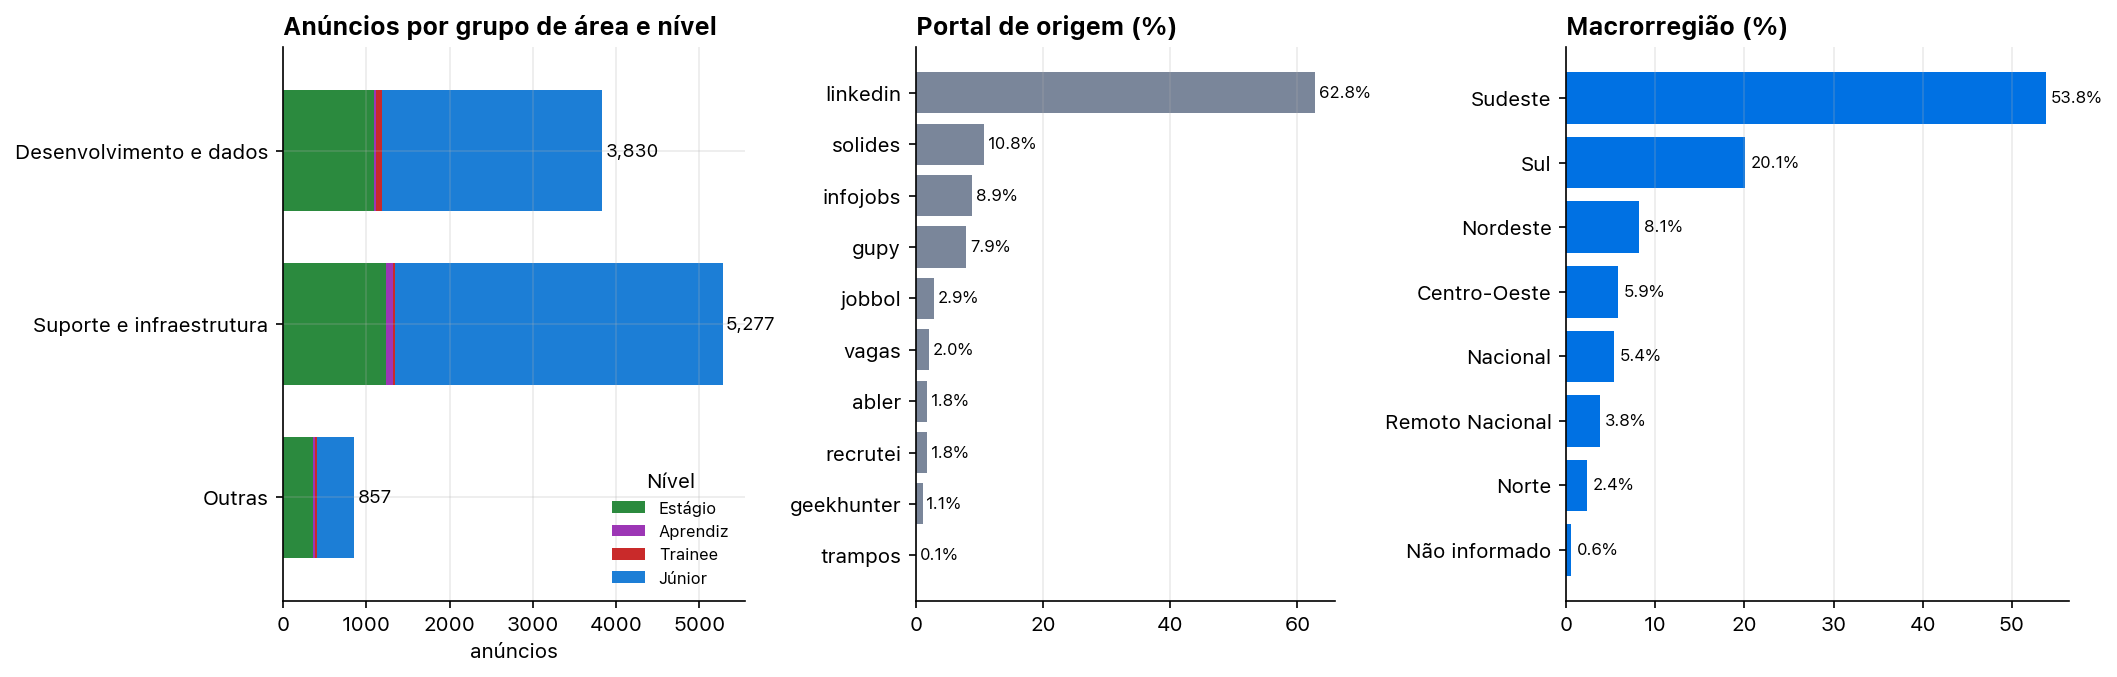

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1.2]})
# grupos x níveis
t = df.groupby(["grupo", "nivel"]).size().unstack(fill_value=0).reindex(index=L.ORDEM_GRUPOS, columns=L.ORDEM_NIVEIS)
t.plot(kind="barh", stacked=True, ax=axes[0], color=[L.PALETA_NIVEL[c] for c in t.columns], width=.7)
axes[0].invert_yaxis(); axes[0].set_title("Anúncios por grupo de área e nível"); axes[0].set_ylabel(""); axes[0].set_xlabel("anúncios")
for i, (g, tot) in enumerate(t.sum(axis=1).items()):
    axes[0].text(tot + 40, i, f"{tot:,}", va="center", fontsize=9)
axes[0].legend(title="Nível", fontsize=8)
# fonte
f = df["fonte"].value_counts(normalize=True).mul(100)
axes[1].barh(f.index[::-1], f.values[::-1], color="#7A869A"); axes[1].set_title("Portal de origem (%)")
for i, v in enumerate(f.values[::-1]): axes[1].text(v + .6, i, f"{v:.1f}%", va="center", fontsize=8)
axes[1].grid(axis="y", visible=False)
# região
r = df["regiao"].astype(str).value_counts(normalize=True).mul(100)
axes[2].barh(r.index[::-1], r.values[::-1], color="#0071E3"); axes[2].set_title("Macrorregião (%)")
for i, v in enumerate(r.values[::-1]): axes[2].text(v + .6, i, f"{v:.1f}%", va="center", fontsize=8)
axes[2].grid(axis="y", visible=False)
L.salvar(fig, "00_composicao_amostra"); plt.show()

**Atenção:** *Aprendiz* e *Trainee* têm poucos casos, sobretudo em Desenvolvimento e dados. Nos notebooks seguintes as
comparações formais entre níveis usam **Estágio vs. Júnior**; as demais células aparecem hachuradas e sem peso interpretativo.

In [4]:
n_niv = df.groupby(["grupo", "nivel"]).size().unstack(fill_value=0).reindex(index=L.ORDEM_GRUPOS, columns=L.ORDEM_NIVEIS)
display(n_niv.style.background_gradient(cmap="Blues", axis=None).set_caption("Anúncios por grupo × nível"))

nivel,Estágio,Aprendiz,Trainee,Júnior
grupo,,,,
Desenvolvimento e dados,1090,24,75,2641
Suporte e infraestrutura,1240,84,22,3931
Outras,356,31,21,449


## 3. Tamanho do texto por portal e o problema da padronização

Anúncios mais longos citam mais competências. Como o tamanho médio varia muito entre portais, as comparações do artigo
são padronizadas por **quartis de tamanho do texto** (Seção 3.5). Os quartis abaixo são calculados sobre o texto **após**
o recorte de benefícios.

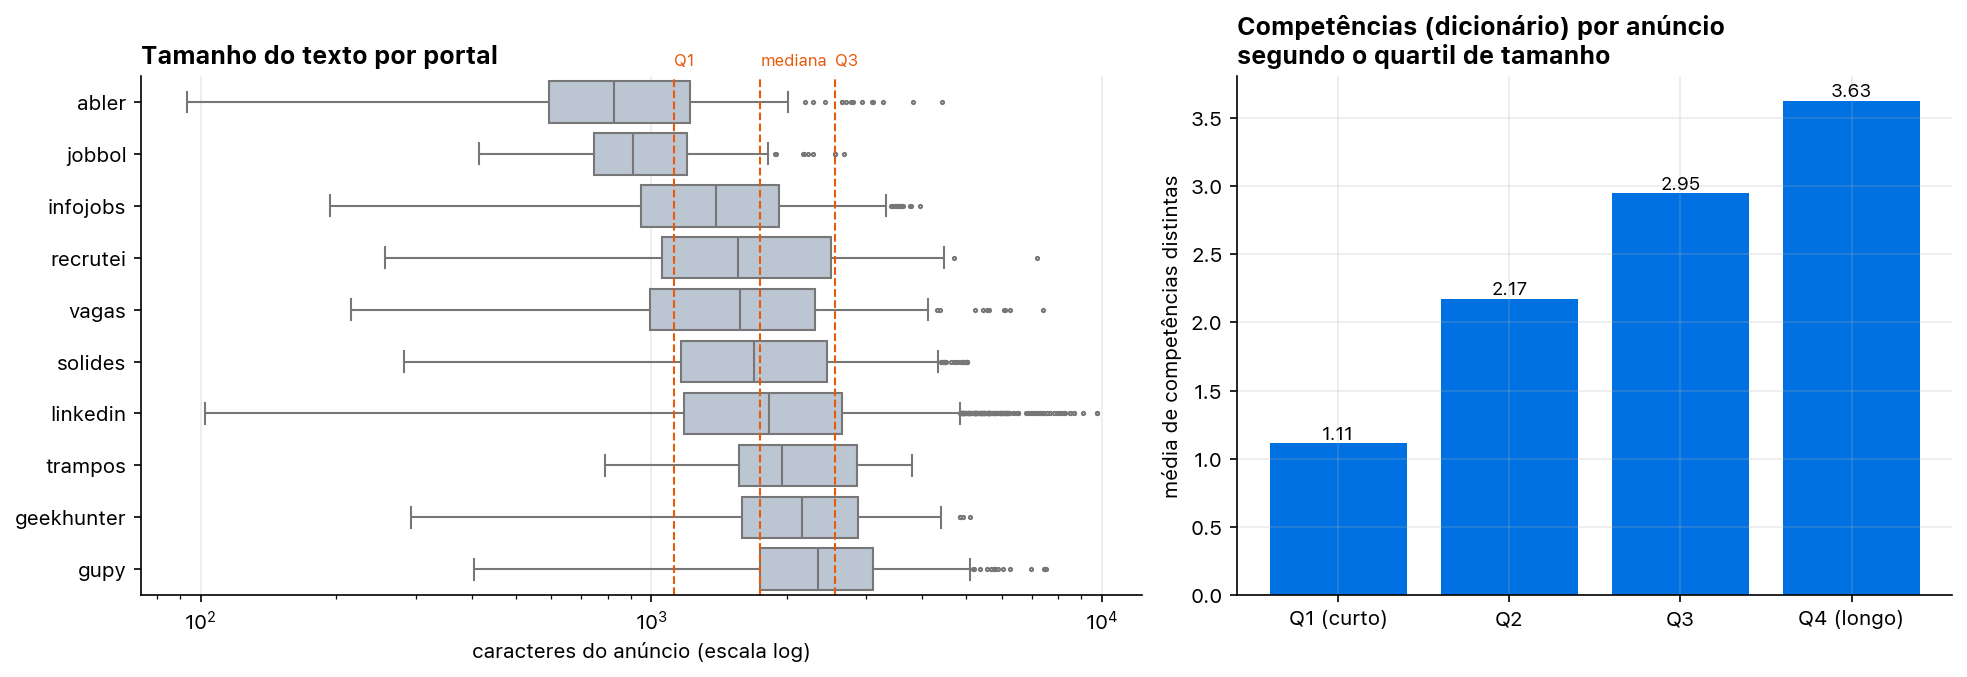

Cortes dos quartis (caracteres): [1122, 1748, 2553] | correlação tamanho × nº de competências: 0.39


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
ordem = df.groupby("fonte")["n_chars_aparado"].median().sort_values().index
sns.boxplot(data=df, y="fonte", x="n_chars_aparado", order=ordem, ax=axes[0], color="#B8C4D6", fliersize=1.5, linewidth=1)
axes[0].set_xscale("log"); axes[0].set_xlabel("caracteres do anúncio (escala log)"); axes[0].set_ylabel("")
axes[0].set_title("Tamanho do texto por portal")
q = df["n_chars_aparado"].quantile([.25, .5, .75])
for v in q: axes[0].axvline(v, color="#E8590C", lw=1, ls="--")
axes[0].text(q.iloc[0], -0.7, "Q1", color="#E8590C", fontsize=8); axes[0].text(q.iloc[1], -0.7, "mediana", color="#E8590C", fontsize=8)
axes[0].text(q.iloc[2], -0.7, "Q3", color="#E8590C", fontsize=8)
nc = df.groupby("quartil_tam", observed=True)["n_comp"].agg(["mean", "count"])
axes[1].bar(nc.index.astype(str), nc["mean"], color="#0071E3")
for i, (m, c) in enumerate(zip(nc["mean"], nc["count"])): axes[1].text(i, m + .03, f"{m:.2f}", ha="center", fontsize=9)
axes[1].set_title("Competências (dicionário) por anúncio\nsegundo o quartil de tamanho"); axes[1].set_ylabel("média de competências distintas")
L.salvar(fig, "00_tamanho_texto"); plt.show()
print("Cortes dos quartis (caracteres):", [int(v) for v in q],
      "| correlação tamanho × nº de competências:", round(df[["n_chars_aparado", "n_comp"]].corr().iloc[0, 1], 2))

O número de competências cresce de forma monotônica com o tamanho. Sem padronização, portais com textos longos
(Gupy, LinkedIn) pareceriam exigir mais do que portais com textos curtos (Abler, Jobbol), apenas por escrever mais.

## 4. Recorte de benefícios e processo seletivo (Seção 3.4)

O artigo diz que o texto foi recortado "a partir das seções de benefícios e de informações sobre o processo seletivo, com
as mesmas regras adotadas pelo projeto de origem". As descrições chegam sem quebras de linha, então aqui foi implementada
uma **aproximação** das regras `secoes_descarte.yml` e `secoes_conteudo.yml` do repositório: um título só vale se começa com maiúscula ou é seguido de `:`.
O recorte vai do título de benefícios até o próximo título de conteúdo (requisitos, atividades, etc.).

Anúncios com algum trecho removido: 50.2% | mediana de caracteres removidos (entre os alterados): 469


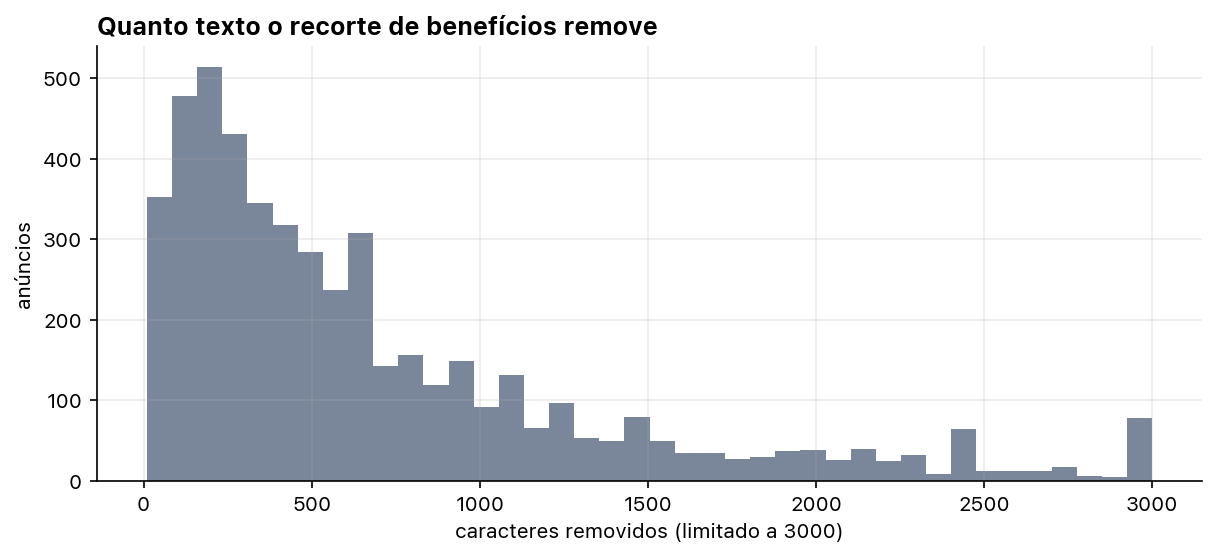

In [6]:
alt = df["n_chars"] != df["n_chars_aparado"]
rem = (df["n_chars"] - df["n_chars_aparado"])[alt]
print(f"Anúncios com algum trecho removido: {alt.mean():.1%} | mediana de caracteres removidos (entre os alterados): {rem.median():.0f}")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(rem.clip(upper=3000), bins=40, color="#7A869A"); ax.set_xlabel("caracteres removidos (limitado a 3000)"); ax.set_ylabel("anúncios")
ax.set_title("Quanto texto o recorte de benefícios remove"); plt.show()

## 5. Dicionário de competências (Seção 3.4-c)

Implementação do dicionário descrito no artigo. As expressões regulares foram escritas com qualificadores
(por exemplo, *"boa comunicação"* e não só *"comunicação"*) para reduzir falsos positivos institucionais.
**A precisão ainda precisa ser medida por duas pessoas** (`[P11]`): o notebook `02` gera a planilha de validação com 15 trechos por competência.
A dimensão *metacognitiva* tem uma única competência no artigo; uma extensão opcional aparece separada no notebook `02`.

In [7]:
linhas = [{"Dimensão": v[0], "Competência": v[1], "Expressão regular (texto sem acento, minúsculo)": v[2]}
          for k, v in L.COMPETENCIAS.items()]
tab = pd.DataFrame(linhas)
display(tab.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "11px"}))

Dimensão,Competência,"Expressão regular (texto sem acento, minúsculo)"
Cognitiva,Resolução de problemas,resolu[cç]ao de problema|resolver problema|solu[cç]ao de problema|solucionar problema|problem[- ]solving|resolu[cç]ao de desafios
Cognitiva,Pensamento analítico e crítico,pensamento (analitico|critico|sistemico)|raciocinio (logico|analitico)|capacidade analitica|perfil analitico|visao analitica|senso critico|analise critica|espirito critico|olhar analitico|analitic[oa]\b
Cognitiva,Atenção aos detalhes,aten[cç]ao (aos? )?detalhes?|detalhista|orientad[oa] a detalhes|cuidado com (os )?detalhes|olhar (atento|criterioso)
Socioemocional,Comunicação,(boa|otima|excelente|clara|eficaz|efetiva|assertiva|forte|bom|boas) (capacidade de )?comunica[cç]ao|comunica[cç]ao (clara|eficaz|efetiva|assertiva|verbal|escrita|interpessoal|oral|objetiva)|(habilidade|capacidade|facilidade|desenvoltura)\w* (de|em|para) (se )?comunica\w*|se comunicar|comunicativ[oa]|comunicar[- ]se
Socioemocional,Trabalho em equipe e colaboração,trabalho em (equipe|time|grupo)|trabalhar em (equipe|time|grupo)|colaborac(ao|oes)|colaborativ|espirito (de )?(equipe|time)|cooperac|team ?player|teamwork|trabalhar de forma (colaborativa|integrada)
Socioemocional,Relacionamento interpessoal e empatia,relacionamento interpessoal|habilidades? interpessoais?|bom relacionamento|empatia|empatic[oa]|inteligencia emocional|sociavel|cordial\w*|cortes\b|educad[oa]\b
Socioemocional,Proatividade e iniciativa,pro-?ativ\w*|\biniciativa\b|protagonis\w*|senso de dono|ownership
Socioemocional,Autonomia,autonom\w*|trabalhar de forma independente|autogerenci\w*|autossuficien\w*
Socioemocional,Organização e gestão do tempo,gest[ao]o do tempo|gerenciamento do tempo|gerenciar (o )?(seu )?tempo|organizad[oa]s?\b|(boa|otima|excelente|forte|senso de|capacidade de|habilidade de|com) organiza[cç]ao|organiza[cç]ao e (planejamento|disciplina|foco|prioriza\w*|gestao)|prioriza[cr]\w*|cumpri(r|mento de) prazos?|gest[ao]o de prazos
Socioemocional,Adaptabilidade e resiliência,adaptab\w*|se adaptar|adaptar[- ]se|capacidade de adapta\w*|flexibilidade(?! de hor| no hor| de jornada)|resilien\w*|trabalhar sob pressao|lidar com (pressao|mudancas)|ambientes? (dinamicos?|de mudancas)


**Competência técnica** = pelo menos uma habilidade da taxonomia do projeto, exceto idiomas (Inglês, Espanhol).
Essa exclusão é escolha desta análise e deve ser validada.

## 6. Distribuição temporal (apenas para documentar a limitação)

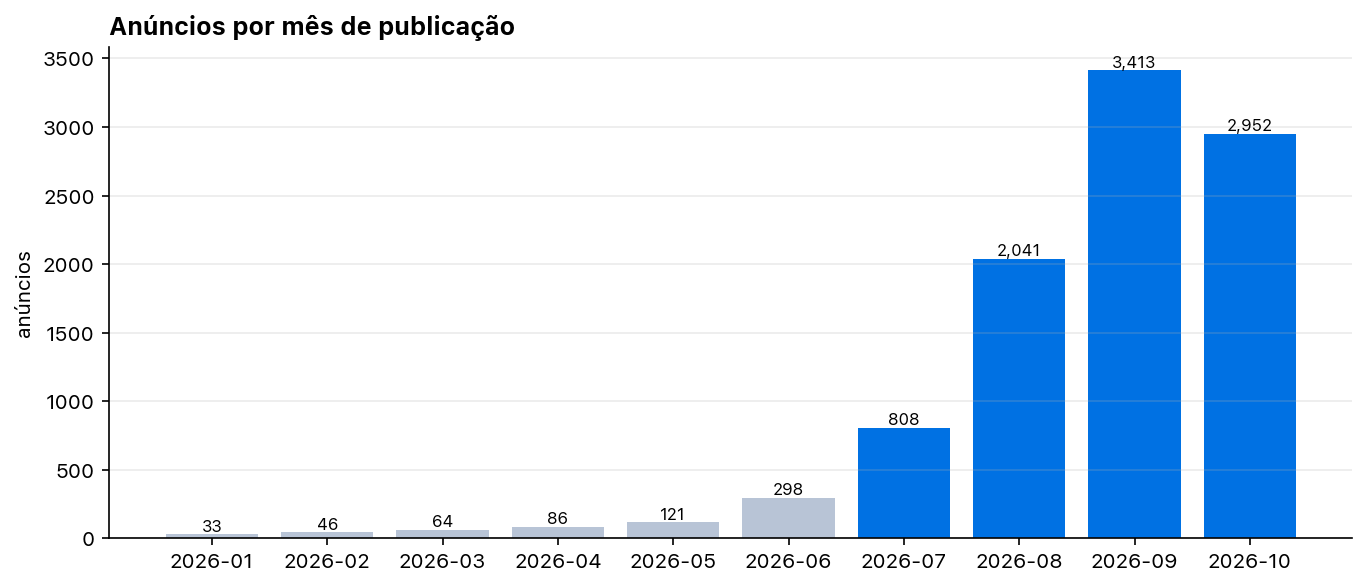

Anúncios publicados entre ago e out/2026: 84% (o artigo cita 86%)


In [8]:
mes = df["data_pub"].dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(mes.index.astype(str), mes.values, color=["#B8C4D6" if v < 500 else "#0071E3" for v in mes.values])
for i, v in enumerate(mes.values): ax.text(i, v + 20, f"{v:,}", ha="center", fontsize=8)
ax.set_title("Anúncios por mês de publicação"); ax.set_ylabel("anúncios"); ax.grid(axis="x", visible=False)
L.salvar(fig, "00_distribuicao_temporal"); plt.show()
print(f"Anúncios publicados entre ago e out/2026: {df['data_pub'].between('2026-08-01', '2026-10-31').mean():.0%} (o artigo cita 86%)")

O volume cresce porque **a coleta se expandiu**, não necessariamente porque o mercado cresceu. Por isso este conjunto de
notebooks nunca compara meses entre si. Isso é coerente com a decisão do artigo de tratar a base como corte transversal.